# 14_ROCOv2_Ablation_Study

**Purpose:** Close the largest experimental gap identified in the
Chapter 4/5 methodology audit — no ablation study existed anywhere in
Notebooks 01-13. This notebook adds two independent ablations:

**Part A — Caption ablation.** Trains a new **Image-only Proposed VLM**
variant: the identical BiomedCLIP vision tower, the identical two-stage
transfer-learning schedule and hyperparameters as Notebook 07, but with
the text tower never called and the classification head operating on the
512-dimensional image embedding alone (not the 1024-dimensional fused
embedding). This isolates the causal contribution of caption input to the
Proposed VLM's point-prediction performance, which Notebook 07's own
results could not do on their own (Section 4.5.3's caption-assisted-
evaluation caveat was previously only a qualitative concern, not a
quantified one).

**Part B — Caption-ablation comparison.** Re-derives both the new
Image-only VLM's and the existing Image+caption VLM's (Notebook 07)
point-prediction metrics on the **same Test-final sample set** (Notebook
08), and runs a paired bootstrap significance test between them —
mirroring Notebook 13's methodology exactly.

**Part C — Trust-score component ablation.** Uses Notebook 11's own
already-saved per-sample-label trust-score components
(`trust_scores_per_sample_label.csv` already contains `Conformal_Component`
and `Counterfactual_Component` broken out, plus `Original_Prob` and
`True_Label`) to build three additional trust-score variants — conformal
component alone, counterfactual component alone, and a raw-model-
confidence-only baseline (`|prob - 0.5| * 2`) — and validates each with
the identical quintile-bin-accuracy + Spearman-correlation methodology
Notebook 11 used for the full composite score. This directly tests
whether the composite trust score's conformal and counterfactual
components each contribute something beyond raw prediction confidence
alone, not just whether the composite score "works" in isolation.

### Scope note — an addition beyond what was requested
The raw-confidence-only baseline in Part C was not one of the four
explicitly requested ablation arms (image-only VLM, image+caption VLM,
trust score without conformal, trust score without counterfactual). It is
added here because, without it, "conformal-only" and "counterfactual-only"
cannot on their own demonstrate that the trust framework contributes
something *beyond the underlying model's raw prediction confidence* —
only a raw-confidence comparison point can establish that. This is stated
here explicitly rather than added silently.

### What this notebook does NOT do
Does not modify Notebooks 01-13 or any of their saved artifacts. Does not
recalibrate conformal thresholds or re-run the counterfactual search —
Part C reuses Notebook 08's and Notebook 09's already-saved, already-
converged results exactly as they are. Test-final is used here only for
final, frozen evaluation of the new Image-only VLM (Part B), exactly as
Notebook 08 established: never for training, early stopping, or
threshold selection.

### Inputs
- `Prepared/train_prepared.csv`, `validation_prepared.csv`,
  `test_prepared.csv`, `test_final_prepared.csv`, `label_mapping.json`.
- Original ROCOv2 Train/Validation/Test image ZIPs (read-only).
- `Prepared/Baselines/BiomedCLIP_VLM_Trained/vlm_predictions.csv` (Notebook 07).
- `Prepared/TrustScore/trust_scores_per_sample_label.csv` (Notebook 11).

### Outputs
New artifacts under `Prepared/Ablation/` — see the manifest cell at the
end of this notebook for the complete list.

### Resumability
Part A (the only part that trains) follows the identical resumable
checkpoint design as Notebooks 05/07: an existing checkpoint in its own
directory is loaded and training continues from its recorded state rather
than being silently overwritten.

In [1]:
# ============================================================
# CELL 1 — CONFIGURATION, PATHS, AND REPRODUCIBILITY
# ============================================================

import os
import io
import sys
import json
import time
import random
import shutil
import zipfile
import warnings
import platform
import subprocess
import itertools
from pathlib import Path

import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")

try:
    from google.colab import drive
    drive.mount("/content/drive", force_remount=False)
    IN_COLAB = True
    print("Google Drive available.")
except ImportError:
    IN_COLAB = False
    print("Not running in Google Colab.")

ROCO_ROOT = Path("/content/drive/MyDrive/ROCOv2")
PREPARED_DIR = ROCO_ROOT / "Prepared"

VLM_TRAINED_DIR = PREPARED_DIR / "Baselines" / "BiomedCLIP_VLM_Trained"
TRUST_SCORE_DIR = PREPARED_DIR / "TrustScore"

ABLATION_DIR = PREPARED_DIR / "Ablation"
IMAGE_ONLY_DIR = ABLATION_DIR / "ImageOnly_VLM"
IMAGE_ONLY_CKPT_DIR = IMAGE_ONLY_DIR / "checkpoints"
IMAGE_ONLY_FIG_DIR = IMAGE_ONLY_DIR / "figures"
ABLATION_FIG_DIR = ABLATION_DIR / "figures"
for d in [ABLATION_DIR, IMAGE_ONLY_DIR, IMAGE_ONLY_CKPT_DIR, IMAGE_ONLY_FIG_DIR, ABLATION_FIG_DIR]:
    d.mkdir(parents=True, exist_ok=True)

TRAIN_PREPARED_PATH = PREPARED_DIR / "train_prepared.csv"
VALID_PREPARED_PATH = PREPARED_DIR / "validation_prepared.csv"
TEST_PREPARED_PATH = PREPARED_DIR / "test_prepared.csv"
TEST_FINAL_PREPARED_PATH = PREPARED_DIR / "test_final_prepared.csv"
LABEL_MAPPING_PATH = PREPARED_DIR / "label_mapping.json"

VLM_PREDICTIONS_PATH = VLM_TRAINED_DIR / "vlm_predictions.csv"
TRUST_SCORES_PATH = TRUST_SCORE_DIR / "trust_scores_per_sample_label.csv"

IMAGE_ZIP_FILES = {
    "train": ROCO_ROOT / "Train" / "Images" / "train_images.zip",
    "validation": ROCO_ROOT / "Validation" / "Images" / "valid_images.zip",
    "test": ROCO_ROOT / "Test" / "Images" / "test_images.zip",
}

# --- Part A artifact paths (Image-only VLM) ---
IMG_CONFIG_PATH = IMAGE_ONLY_DIR / "ablation_image_only_vlm_config.json"
IMG_HISTORY_PATH = IMAGE_ONLY_DIR / "ablation_image_only_vlm_training_history.csv"
IMG_VAL_METRICS_PATH = IMAGE_ONLY_DIR / "ablation_image_only_vlm_validation_metrics.csv"
IMG_TEST_METRICS_PATH = IMAGE_ONLY_DIR / "ablation_image_only_vlm_test_metrics.csv"
IMG_PER_LABEL_METRICS_PATH = IMAGE_ONLY_DIR / "ablation_image_only_vlm_per_label_metrics.csv"
IMG_PREDICTIONS_PATH = IMAGE_ONLY_DIR / "ablation_image_only_vlm_predictions.csv"
IMG_BEST_MODEL_PATH = IMAGE_ONLY_CKPT_DIR / "ablation_image_only_vlm_best_model.pt"
IMG_LAST_MODEL_PATH = IMAGE_ONLY_CKPT_DIR / "ablation_image_only_vlm_last_model.pt"
IMG_LEARNING_CURVES_PDF = IMAGE_ONLY_FIG_DIR / "learning_curves.pdf"
IMG_LEARNING_CURVES_PNG = IMAGE_ONLY_FIG_DIR / "learning_curves_300dpi.png"
IMG_REPRODUCIBILITY_PATH = IMAGE_ONLY_DIR / "reproducibility.json"
IMG_MANIFEST_PATH = IMAGE_ONLY_DIR / "artifact_manifest.json"
IMG_CORRUPT_LOG_PATH = IMAGE_ONLY_DIR / "corrupt_samples_skipped_during_training.jsonl"

# --- Part B artifact paths (caption-ablation comparison) ---
CAPTION_COMPARISON_OVERALL_PATH = ABLATION_DIR / "ablation_caption_comparison_overall.csv"
CAPTION_COMPARISON_PER_LABEL_PATH = ABLATION_DIR / "ablation_caption_comparison_per_label.csv"
CAPTION_BOOTSTRAP_CI_PATH = ABLATION_DIR / "ablation_caption_bootstrap_ci.csv"
CAPTION_COMPARISON_FIGURE_PDF = ABLATION_FIG_DIR / "caption_ablation_comparison.pdf"
CAPTION_COMPARISON_FIGURE_PNG = ABLATION_FIG_DIR / "caption_ablation_comparison_300dpi.png"

# --- Part C artifact paths (trust-score component ablation) ---
TRUST_VARIANT_VALIDATION_PATH = ABLATION_DIR / "ablation_trust_score_variant_validation.csv"
TRUST_VARIANT_SUMMARY_PATH = ABLATION_DIR / "ablation_trust_score_variant_summary.csv"
TRUST_VARIANT_FIGURE_PDF = ABLATION_FIG_DIR / "trust_score_component_ablation.pdf"
TRUST_VARIANT_FIGURE_PNG = ABLATION_FIG_DIR / "trust_score_component_ablation_300dpi.png"

REPRODUCIBILITY_PATH = ABLATION_DIR / "reproducibility.json"
MANIFEST_PATH = ABLATION_DIR / "artifact_manifest.json"

ALLOW_OVERWRITE = False

def safe_save_json(path, obj, allow_overwrite=None):
    allow_overwrite = ALLOW_OVERWRITE if allow_overwrite is None else allow_overwrite
    if path.exists() and not allow_overwrite:
        raise FileExistsError(
            f"Refusing to overwrite existing artifact:\n{path}\n\n"
            "Remove/rename it or explicitly set ALLOW_OVERWRITE=True after review."
        )
    with open(path, "w", encoding="utf-8") as f:
        json.dump(obj, f, indent=2, default=str)
    print("Saved:", path)

def safe_save_csv(path, df, allow_overwrite=None):
    allow_overwrite = ALLOW_OVERWRITE if allow_overwrite is None else allow_overwrite
    if path.exists() and not allow_overwrite:
        raise FileExistsError(
            f"Refusing to overwrite existing artifact:\n{path}\n\n"
            "Remove/rename it or explicitly set ALLOW_OVERWRITE=True after review."
        )
    df.to_csv(path, index=False)
    print("Saved:", path)

SEED = 42

def set_global_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    try:
        import torch
        torch.manual_seed(seed)
        if torch.cuda.is_available():
            torch.cuda.manual_seed(seed)
            torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False
    except ImportError:
        pass

set_global_seed(SEED)

print("=" * 80)
print("NOTEBOOK 14 — ABLATION STUDY")
print("=" * 80)
print("ROCO_ROOT:", ROCO_ROOT)
print("ABLATION_DIR:", ABLATION_DIR)
print("Random seed:", SEED)


Mounted at /content/drive
Google Drive available.
NOTEBOOK 14 — ABLATION STUDY
ROCO_ROOT: /content/drive/MyDrive/ROCOv2
ABLATION_DIR: /content/drive/MyDrive/ROCOv2/Prepared/Ablation
Random seed: 42


## 1. Verify required inputs

In [3]:
# ============================================================
# CELL 2 — REQUIRED INPUT ARTIFACT CHECK
# ============================================================

required_inputs = {
    "train_prepared.csv": TRAIN_PREPARED_PATH,
    "validation_prepared.csv": VALID_PREPARED_PATH,
    "test_prepared.csv": TEST_PREPARED_PATH,
    "test_final_prepared.csv": TEST_FINAL_PREPARED_PATH,
    "label_mapping.json": LABEL_MAPPING_PATH,
    "vlm_predictions.csv (Notebook 07)": VLM_PREDICTIONS_PATH,
    "trust_scores_per_sample_label.csv (Notebook 11)": TRUST_SCORES_PATH,
}

missing_inputs = [f"{name}: {path}" for name, path in required_inputs.items() if not path.exists()]
if missing_inputs:
    raise FileNotFoundError(
        "Required Notebook 14 input artifacts are missing:\n\n" + "\n".join(missing_inputs)
        + "\n\nRun 02, 07, 08, 09, and 11 first."
    )

for name, path in IMAGE_ZIP_FILES.items():
    if not path.exists():
        raise FileNotFoundError(f"Original image ZIP missing for {name}: {path}")

print("PASS — Required upstream artifacts and original image ZIPs exist.")
for name, path in required_inputs.items():
    print(f"{name:45s}: {path}")


PASS — Required upstream artifacts and original image ZIPs exist.
train_prepared.csv                           : /content/drive/MyDrive/ROCOv2/Prepared/train_prepared.csv
validation_prepared.csv                      : /content/drive/MyDrive/ROCOv2/Prepared/validation_prepared.csv
test_prepared.csv                            : /content/drive/MyDrive/ROCOv2/Prepared/test_prepared.csv
test_final_prepared.csv                      : /content/drive/MyDrive/ROCOv2/Prepared/test_final_prepared.csv
label_mapping.json                           : /content/drive/MyDrive/ROCOv2/Prepared/label_mapping.json
vlm_predictions.csv (Notebook 07)            : /content/drive/MyDrive/ROCOv2/Prepared/Baselines/BiomedCLIP_VLM_Trained/vlm_predictions.csv
trust_scores_per_sample_label.csv (Notebook 11): /content/drive/MyDrive/ROCOv2/Prepared/TrustScore/trust_scores_per_sample_label.csv


## 2. Load the authoritative split, label taxonomy, and captions

In [4]:
# ============================================================
# CELL 3 — LOAD SPLITS AND LABEL MAPPING
# ============================================================

split_dfs = {
    "train": pd.read_csv(TRAIN_PREPARED_PATH),
    "validation": pd.read_csv(VALID_PREPARED_PATH),
    "test": pd.read_csv(TEST_PREPARED_PATH),
}
test_final_df = pd.read_csv(TEST_FINAL_PREPARED_PATH)
test_final_ids = set(test_final_df["ID"].astype(str))

with open(LABEL_MAPPING_PATH, "r", encoding="utf-8") as f:
    label_mapping = json.load(f)

assert len(label_mapping) == 18, "Authoritative label_mapping.json must contain exactly 18 labels."
LABEL_COLUMNS = [f"label_{cui}" for cui, _ in sorted(label_mapping.items(), key=lambda kv: kv[1])]
N_LABELS = len(LABEL_COLUMNS)

CANONICAL_LABEL_NAMES = {
    "C0000726": "Abdomen", "C0002978": "Angiogram", "C0006141": "Breast",
    "C0023216": "Lower Extremity", "C0024485": "Magnetic Resonance Imaging",
    "C0030797": "Pelvis", "C0032743": "Positron-Emission Tomography",
    "C0037303": "Bone structure of cranium", "C0037949": "Vertebral column",
    "C0040405": "X-Ray Computed Tomography", "C0041618": "Ultrasonography",
    "C0205106": "Transverse", "C0205129": "Sagittal", "C0817096": "Chest",
    "C1140618": "Upper Extremity", "C1306645": "Plain x-ray",
    "C1996865": "Postero-Anterior", "C1999039": "Anterior-Posterior",
}
LABEL_NAMES = [
    CANONICAL_LABEL_NAMES.get(cui, cui)
    for cui, _ in sorted(label_mapping.items(), key=lambda kv: kv[1])
]

print("=" * 80)
print("AUTHORITATIVE SPLIT (from disk)")
print("=" * 80)
for split_name, df in split_dfs.items():
    print(f"{split_name.capitalize():12s}: {len(df):,} rows")
print(f"Test-final   : {len(test_final_df):,} rows (subset of test, from Notebook 08)")
print(f"\nLabel taxonomy ({N_LABELS} labels) loaded.")


AUTHORITATIVE SPLIT (from disk)
Train       : 59,666 rows
Validation  : 9,819 rows
Test        : 9,870 rows
Test-final   : 4,935 rows (subset of test, from Notebook 08)

Label taxonomy (18 labels) loaded.


# PART A — CAPTION ABLATION: TRAIN THE IMAGE-ONLY PROPOSED VLM

## 3. Load BiomedCLIP (fixed checkpoint — same as Notebook 07)

Only the vision tower (`biomedclip_model.visual`) will ever be trained or
called in Part A. The text tower is loaded (since it is part of the same
checkpoint object) but is never invoked in any forward pass and is never
included in any optimizer parameter group below — it plays no role in
this variant's predictions.

In [5]:
# ============================================================
# CELL 4 — LOAD BIOMEDCLIP (vision tower only will be used)
# ============================================================

import torch
import torch.nn as nn
import torch.nn.functional as F

BIOMEDCLIP_CHECKPOINT = "hf-hub:microsoft/BiomedCLIP-PubMedBERT_256-vit_base_patch16_224"

try:
    import open_clip
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "open_clip_torch"], check=True)
    import open_clip

try:
    biomedclip_model, biomedclip_preprocess = open_clip.create_model_from_pretrained(BIOMEDCLIP_CHECKPOINT)
    biomedclip_tokenizer = open_clip.get_tokenizer(BIOMEDCLIP_CHECKPOINT)
except Exception as exc:
    raise RuntimeError(
        f"Could not load the required VLM checkpoint '{BIOMEDCLIP_CHECKPOINT}'.\n"
        "This notebook does not silently fall back to a different VLM.\n"
        f"Underlying error: {type(exc).__name__}: {exc}"
    )

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
biomedclip_model = biomedclip_model.to(device)

# Start fully frozen — Cell 10 controls staged unfreezing of the vision tower only.
for _p in biomedclip_model.parameters():
    _p.requires_grad = False

with torch.no_grad():
    _dummy_tokens = biomedclip_tokenizer(["dummy"]).to(device)
    EMBED_DIM = int(biomedclip_model.encode_text(_dummy_tokens).shape[-1])

assert hasattr(biomedclip_model, "visual"), (
    "biomedclip_model has no '.visual' submodule — this open_clip version's CLIP "
    "class structure differs from what this notebook assumes. Do not proceed "
    "without confirming how to isolate the vision tower's parameters."
)

print("Loaded checkpoint:", BIOMEDCLIP_CHECKPOINT)
print("Device:", device)
print("Embedding dimension (per tower):", EMBED_DIM)
print("Image preprocessing: BiomedCLIP's own pretrained transform (same as Notebook 07).")
print("Text tower will NOT be called anywhere in Part A of this notebook.")


open_clip_config.json:   0%|          | 0.00/707 [00:00<?, ?B/s]

open_clip_pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  784MB            

open_clip_pytorch_model.bin: downloading bytes:           |  0.00B            

config.json:   0%|          | 0.00/385 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/28.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/225k [00:00<?, ?B/s]

Loaded checkpoint: hf-hub:microsoft/BiomedCLIP-PubMedBERT_256-vit_base_patch16_224
Device: cuda
Embedding dimension (per tower): 512
Image preprocessing: BiomedCLIP's own pretrained transform (same as Notebook 07).
Text tower will NOT be called anywhere in Part A of this notebook.


## 4. Training configuration

Identical to Notebook 07's `TRAINING_CONFIG` in every hyperparameter that
Notebook 07 itself controls (batch size, learning rates, epoch budgets,
optimizer, scheduler, loss, pos_weight cap, threshold, seed) — the sole
architectural difference is `fusion_dim`, which here equals a single
tower's embedding dimension rather than two towers concatenated. This is
a controlled ablation: everything Notebook 07 could have kept fixed, is
kept fixed.

In [6]:
# ============================================================
# CELL 5 — TRAINING CONFIGURATION (mirrors Notebook 07 exactly, minus fusion)
# ============================================================

TRAINING_CONFIG = {
    "seed": SEED,
    "embed_dim": EMBED_DIM,
    "fusion_dim": EMBED_DIM,  # image embedding only — no concatenation with text
    "batch_size": 16,
    "num_workers": 2,
    "pin_memory": True,
    "stage1_max_epochs": 3,
    "stage1_lr": 1e-3,
    "stage2_max_epochs": 15,
    "stage2_lr": 2e-6,
    "optimizer": "AdamW",
    "weight_decay": 1e-4,
    "scheduler": "ReduceLROnPlateau(mode='max', factor=0.5, patience=2, on=validation_macro_f1)",
    "min_lr": 1e-8,
    "early_stopping_metric": "validation_macro_f1",
    "early_stopping_patience": 5,
    "gradient_clip_norm": 1.0,
    "mixed_precision": "auto (torch.cuda.amp if CUDA available, else disabled)",
    "loss": "BCEWithLogitsLoss(pos_weight=train-only, capped)",
    "pos_weight_cap": 20.0,
    "decision_threshold": 0.5,
    "threshold_strategy": "Fixed at 0.5 — same convention as Notebooks 05/07, no optimization performed.",
    "checkpoint_dir": str(IMAGE_ONLY_CKPT_DIR),
    "ablation_note": (
        "Identical hyperparameters to Notebook 07's Proposed VLM (batch size, "
        "both stages' LR and max epochs, optimizer, scheduler, loss, pos_weight "
        "cap, threshold, seed). The only differences are architectural: the text "
        "tower is never called, the classification head takes a single "
        "EMBED_DIM-sized image embedding instead of a 2*EMBED_DIM fused "
        "embedding, and only biomedclip_model.visual's parameters (plus the "
        "head) are ever placed in an optimizer — the text tower's parameters "
        "are excluded entirely, not merely left with zero gradient, so AdamW's "
        "decoupled weight decay cannot silently perturb them either."
    ),
}

print("=" * 80)
print("TRAINING CONFIGURATION (Image-only Proposed VLM)")
print("=" * 80)
for k, v in TRAINING_CONFIG.items():
    print(f"{k:28s}: {v}")


TRAINING CONFIGURATION (Image-only Proposed VLM)
seed                        : 42
embed_dim                   : 512
fusion_dim                  : 512
batch_size                  : 16
num_workers                 : 2
pin_memory                  : True
stage1_max_epochs           : 3
stage1_lr                   : 0.001
stage2_max_epochs           : 15
stage2_lr                   : 2e-06
optimizer                   : AdamW
weight_decay                : 0.0001
scheduler                   : ReduceLROnPlateau(mode='max', factor=0.5, patience=2, on=validation_macro_f1)
min_lr                      : 1e-08
early_stopping_metric       : validation_macro_f1
early_stopping_patience     : 5
gradient_clip_norm          : 1.0
mixed_precision             : auto (torch.cuda.amp if CUDA available, else disabled)
loss                        : BCEWithLogitsLoss(pos_weight=train-only, capped)
pos_weight_cap              : 20.0
decision_threshold          : 0.5
threshold_strategy          : Fixed at 0.5 — sa

## 5. Extract source ZIPs to plain local files (same proven pattern as Notebooks 05/07/09/10)

In [7]:
# ============================================================
# CELL 6 — EXTRACT ZIPS TO PLAIN LOCAL FILES
# ============================================================

LOCAL_IMAGE_DIR = Path("/content/rocov2_images_local")
LOCAL_IMAGE_DIR.mkdir(parents=True, exist_ok=True)

EXTRACTED_IMAGE_DIRS = {
    split_name: LOCAL_IMAGE_DIR / f"{split_name}_extracted"
    for split_name in IMAGE_ZIP_FILES
}

def _extract_if_needed(zip_path, extract_dir, expected_members):
    extract_dir.mkdir(parents=True, exist_ok=True)
    existing = sum(1 for p in extract_dir.rglob("*") if p.is_file())
    if existing >= len(expected_members):
        print(f"Already extracted, skipping: {extract_dir} ({existing:,} files present)")
        return
    print(f"Extracting {zip_path.name} -> {extract_dir} ({len(expected_members):,} members)...")
    with zipfile.ZipFile(zip_path, "r") as zf:
        zf.extractall(extract_dir)
    extracted = sum(1 for p in extract_dir.rglob("*") if p.is_file())
    if extracted != len(expected_members):
        raise IOError(
            f"Extraction count mismatch for {zip_path.name}: expected "
            f"{len(expected_members):,}, found {extracted:,} under {extract_dir}."
        )
    print(f"  done: {extracted:,} files extracted.")

for split_name, zip_path in IMAGE_ZIP_FILES.items():
    with zipfile.ZipFile(zip_path, "r") as _zf:
        _members = [n for n in _zf.namelist() if not n.endswith("/")]
    _extract_if_needed(zip_path, EXTRACTED_IMAGE_DIRS[split_name], _members)

class LocalImageReader:
    def __init__(self, extract_dir):
        self.extract_dir = Path(extract_dir)

    def read_bytes(self, member):
        return (self.extract_dir / member).read_bytes()

image_readers = {
    split_name: LocalImageReader(EXTRACTED_IMAGE_DIRS[split_name])
    for split_name in IMAGE_ZIP_FILES
}

for split_name, df in split_dfs.items():
    sample_row = df.iloc[0]
    raw = image_readers[split_name].read_bytes(sample_row["Image_Member"])
    assert len(raw) > 0, f"{split_name}: read zero bytes for {sample_row['Image_Member']}"

print("PASS — Local image reader verified on one sample per split.")


Extracting train_images.zip -> /content/rocov2_images_local/train_extracted (59,958 members)...
  done: 59,958 files extracted.
Extracting valid_images.zip -> /content/rocov2_images_local/validation_extracted (9,904 members)...
  done: 9,904 files extracted.
Extracting test_images.zip -> /content/rocov2_images_local/test_extracted (9,927 members)...
  done: 9,927 files extracted.
PASS — Local image reader verified on one sample per split.


## 6. Class imbalance and Train-only positive class weighting (identical formula to Notebooks 05/07)

In [8]:
# ============================================================
# CELL 7 — TRAIN-ONLY POSITIVE CLASS WEIGHTS
# ============================================================

train_label_matrix = split_dfs["train"][LABEL_COLUMNS].to_numpy(dtype=np.float64)
n_train = train_label_matrix.shape[0]
pos_counts = train_label_matrix.sum(axis=0)
neg_counts = n_train - pos_counts

raw_pos_weight = neg_counts / np.clip(pos_counts, 1, None)
capped_pos_weight = np.clip(raw_pos_weight, a_min=None, a_max=TRAINING_CONFIG["pos_weight_cap"])
pos_weight_tensor = torch.tensor(capped_pos_weight, dtype=torch.float32)

pos_weight_df = pd.DataFrame({
    "Label_Column": LABEL_COLUMNS, "Raw_Pos_Weight": raw_pos_weight, "Capped_Pos_Weight": capped_pos_weight,
})
display(pos_weight_df)
print(f"pos_weight formula: negative_count / positive_count (Train only), "
      f"capped at {TRAINING_CONFIG['pos_weight_cap']} — identical to Notebooks 05/07.")


,Label_Column,Raw_Pos_Weight,Capped_Pos_Weight
0,label_C0000726,17.786524,17.786524
1,label_C0002978,14.074785,14.074785
2,label_C0006141,454.465649,20.000000
3,label_C0023216,24.541952,20.000000
4,label_C0024485,5.090853,5.090853
5,label_C0030797,21.296712,20.000000
6,label_C0032743,115.535156,20.000000
7,label_C0037303,16.939266,16.939266
8,label_C0037949,45.324534,20.000000
9,label_C0040405,1.911247,1.911247


pos_weight formula: negative_count / positive_count (Train only), capped at 20.0 — identical to Notebooks 05/07.


## 7. Dataset (image + caption returned, caption ignored downstream)

Reuses the same `Dataset` shape as Notebook 07 for consistency (image,
caption, labels, id) so the same retry-and-log reliability pattern
applies identically; the caption string is simply never read by the
Image-only model's forward pass (Cell 12).

In [9]:
# ============================================================
# CELL 8 — DATASET (image + caption + label, caption unused downstream)
# ============================================================

from PIL import Image
from torch.utils.data import Dataset, DataLoader

def _append_corrupt_sample_log(record):
    with open(IMG_CORRUPT_LOG_PATH, "a", encoding="utf-8") as f:
        f.write(json.dumps(record, default=str) + "\n")

class ROCOv2ImageOnlyDataset(Dataset):
    def __init__(self, df, split_name, image_reader, transform, label_columns, max_retries=5):
        self.df = df.reset_index(drop=True)
        self.split_name = split_name
        self.image_reader = image_reader
        self.transform = transform
        self.label_columns = label_columns
        self.max_retries = max_retries

    def __len__(self):
        return len(self.df)

    def _load_item(self, idx):
        row = self.df.iloc[idx]
        raw_bytes = self.image_reader.read_bytes(row["Image_Member"])
        with Image.open(io.BytesIO(raw_bytes)) as img:
            image = self.transform(img.convert("RGB"))
        labels = torch.tensor(row[self.label_columns].to_numpy(dtype=np.float32), dtype=torch.float32)
        return image, labels, row["ID"]

    def __getitem__(self, idx):
        tried_idx = idx
        last_exc = None
        for attempt in range(self.max_retries + 1):
            try:
                return self._load_item(tried_idx)
            except Exception as exc:
                last_exc = exc
                bad_id = self.df.iloc[tried_idx]["ID"]
                print(f"WARNING — [{self.split_name}] unreadable sample skipped: "
                      f"ID={bad_id} ({type(exc).__name__}: {exc}). "
                      f"Substituting a different sample (attempt {attempt + 1}/{self.max_retries}).")
                _append_corrupt_sample_log({
                    "Split": self.split_name, "ID": str(bad_id),
                    "Error": f"{type(exc).__name__}: {exc}", "Timestamp": time.time(),
                })
                tried_idx = random.randrange(len(self.df))
        raise RuntimeError(
            f"[{self.split_name}] Exceeded max_retries={self.max_retries} near index {idx}. "
            f"Last error: {type(last_exc).__name__}: {last_exc}"
        )

print("ROCOv2ImageOnlyDataset defined — image + 18-d multi-hot label (no caption used).")


ROCOv2ImageOnlyDataset defined — image + 18-d multi-hot label (no caption used).


## 8. Datasets and DataLoaders

In [10]:
# ============================================================
# CELL 9 — DATASETS AND DATALOADERS
# ============================================================

datasets = {
    split_name: ROCOv2ImageOnlyDataset(
        df=split_dfs[split_name], split_name=split_name, image_reader=image_readers[split_name],
        transform=biomedclip_preprocess, label_columns=LABEL_COLUMNS,
    )
    for split_name in ["train", "validation", "test"]
}

def seed_worker(worker_id):
    worker_seed = SEED + worker_id
    np.random.seed(worker_seed)
    random.seed(worker_seed)

train_generator = torch.Generator()
train_generator.manual_seed(SEED)

dataloaders = {
    "train": DataLoader(
        datasets["train"], batch_size=TRAINING_CONFIG["batch_size"], shuffle=True,
        num_workers=TRAINING_CONFIG["num_workers"], pin_memory=TRAINING_CONFIG["pin_memory"],
        worker_init_fn=seed_worker, generator=train_generator, drop_last=False,
    ),
    "validation": DataLoader(
        datasets["validation"], batch_size=TRAINING_CONFIG["batch_size"], shuffle=False,
        num_workers=TRAINING_CONFIG["num_workers"], pin_memory=TRAINING_CONFIG["pin_memory"],
        worker_init_fn=seed_worker, drop_last=False,
    ),
    "test": DataLoader(
        datasets["test"], batch_size=TRAINING_CONFIG["batch_size"], shuffle=False,
        num_workers=TRAINING_CONFIG["num_workers"], pin_memory=TRAINING_CONFIG["pin_memory"],
        worker_init_fn=seed_worker, drop_last=False,
    ),
}

for split_name, dl in dataloaders.items():
    print(f"{split_name.capitalize():12s}: {len(datasets[split_name]):,} samples, {len(dl):,} batches")


Train       : 59,666 samples, 3,730 batches
Validation  : 9,819 samples, 614 batches
Test        : 9,870 samples, 617 batches


## 9. Image-only classification head

In [11]:
# ============================================================
# CELL 10 — IMAGE-ONLY CLASSIFICATION HEAD
# ============================================================

classifier_head = nn.Sequential(
    nn.Linear(TRAINING_CONFIG["fusion_dim"], 256),
    nn.ReLU(),
    nn.Dropout(0.2),
    nn.Linear(256, N_LABELS),
).to(device)

for _m in classifier_head.modules():
    if isinstance(_m, nn.Linear):
        nn.init.kaiming_normal_(_m.weight, nonlinearity="relu")
        nn.init.zeros_(_m.bias)

vision_tower_params = sum(p.numel() for p in biomedclip_model.visual.parameters())
head_total_params = sum(p.numel() for p in classifier_head.parameters())
total_trainable_scope_params = vision_tower_params + head_total_params

ARCHITECTURE_INFO = {
    "backbone": "BiomedCLIP vision tower only (fine-tuned); text tower loaded but never called",
    "backbone_checkpoint": BIOMEDCLIP_CHECKPOINT,
    "fusion": "none — single L2-normalized image embedding used directly",
    "classifier_head": "Linear(embed_dim, 256) -> ReLU -> Dropout(0.2) -> Linear(256, 18)",
    "classifier_init": "kaiming_normal_(weight, nonlinearity='relu'); zeros_(bias)",
    "vision_tower_parameters": int(vision_tower_params),
    "head_parameters": int(head_total_params),
    "total_trainable_scope_parameters": int(total_trainable_scope_params),
    "device": str(device),
}

print("=" * 80)
print("IMAGE-ONLY PROPOSED VLM ARCHITECTURE (ABLATION)")
print("=" * 80)
for k, v in ARCHITECTURE_INFO.items():
    print(f"{k:34s}: {v}")
print("\nImage -> BiomedCLIP.encode_image -> L2-normalize -> classifier head -> 18 logits -> sigmoid")
print("Caption: loaded by the Dataset for interface consistency, never passed to the model.")
print("Loss: BCEWithLogitsLoss(pos_weight=...). No softmax anywhere in this notebook.")


IMAGE-ONLY PROPOSED VLM ARCHITECTURE (ABLATION)
backbone                          : BiomedCLIP vision tower only (fine-tuned); text tower loaded but never called
backbone_checkpoint               : hf-hub:microsoft/BiomedCLIP-PubMedBERT_256-vit_base_patch16_224
fusion                            : none — single L2-normalized image embedding used directly
classifier_head                   : Linear(embed_dim, 256) -> ReLU -> Dropout(0.2) -> Linear(256, 18)
classifier_init                   : kaiming_normal_(weight, nonlinearity='relu'); zeros_(bias)
vision_tower_parameters           : 86191872
head_parameters                   : 135954
total_trainable_scope_parameters  : 86327826
device                            : cuda

Image -> BiomedCLIP.encode_image -> L2-normalize -> classifier head -> 18 logits -> sigmoid
Caption: loaded by the Dataset for interface consistency, never passed to the model.
Loss: BCEWithLogitsLoss(pos_weight=...). No softmax anywhere in this notebook.


## 10. Transfer-learning strategy (vision tower only)

Same two-stage structure as Notebook 07: freeze, warm up the new head,
then unfreeze and fine-tune at a much lower learning rate — restricted
here to `biomedclip_model.visual` since the text tower is never used.

In [12]:
# ============================================================
# CELL 11 — TRANSFER-LEARNING STAGE CONTROL (vision tower only)
# ============================================================

def set_vision_trainable(trainable):
    for param in biomedclip_model.visual.parameters():
        param.requires_grad = trainable
    for param in classifier_head.parameters():
        param.requires_grad = True

def count_trainable():
    return (
        sum(p.numel() for p in biomedclip_model.visual.parameters() if p.requires_grad)
        + sum(p.numel() for p in classifier_head.parameters() if p.requires_grad)
    )

TRANSFER_LEARNING_PLAN = {
    "stage_1": {
        "description": "Vision tower frozen; only the new classification head trains.",
        "frozen_layers": "biomedclip_model.visual.* ; biomedclip_model.(text-related) permanently unused",
        "unfrozen_layers": "classifier_head.*",
        "learning_rate": TRAINING_CONFIG["stage1_lr"],
        "max_epochs": TRAINING_CONFIG["stage1_max_epochs"],
    },
    "stage_2": {
        "description": "Vision tower unfrozen and fine-tuned at a much lower learning rate.",
        "frozen_layers": "biomedclip_model.(text-related), permanently — never in any optimizer",
        "unfrozen_layers": "biomedclip_model.visual.* and classifier_head.*",
        "learning_rate": TRAINING_CONFIG["stage2_lr"],
        "max_epochs": TRAINING_CONFIG["stage2_max_epochs"],
    },
}

print("Transfer-learning plan (image-only ablation):")
print(json.dumps(TRANSFER_LEARNING_PLAN, indent=2))


Transfer-learning plan (image-only ablation):
{
  "stage_1": {
    "description": "Vision tower frozen; only the new classification head trains.",
    "frozen_layers": "biomedclip_model.visual.* ; biomedclip_model.(text-related) permanently unused",
    "unfrozen_layers": "classifier_head.*",
    "learning_rate": 0.001,
    "max_epochs": 3
  },
  "stage_2": {
    "description": "Vision tower unfrozen and fine-tuned at a much lower learning rate.",
    "frozen_layers": "biomedclip_model.(text-related), permanently \u2014 never in any optimizer",
    "unfrozen_layers": "biomedclip_model.visual.* and classifier_head.*",
    "learning_rate": 2e-06,
    "max_epochs": 15
  }
}


## 11. Train / eval loop functions (image-only forward pass)

In [13]:
# ============================================================
# CELL 12 — TRAIN / EVAL LOOP FUNCTIONS (IMAGE-ONLY)
# ============================================================

from sklearn.metrics import f1_score

AMP_ENABLED = torch.cuda.is_available()
scaler = torch.cuda.amp.GradScaler(enabled=AMP_ENABLED)
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight_tensor.to(device))

def quick_macro_f1(y_true, y_score, threshold):
    y_pred = (y_score >= threshold).astype(int)
    return f1_score(y_true, y_pred, average="macro", zero_division=0)

def forward_image_only(images):
    image_embeds = F.normalize(biomedclip_model.encode_image(images), dim=-1)
    return classifier_head(image_embeds)

def train_one_epoch(loader, optimizer):
    biomedclip_model.train()
    classifier_head.train()
    running_loss = 0.0
    all_true, all_score = [], []

    for images, labels, _ids in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)
        with torch.cuda.amp.autocast(enabled=AMP_ENABLED):
            logits = forward_image_only(images)
            loss = criterion(logits, labels)

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(
            itertools.chain(biomedclip_model.visual.parameters(), classifier_head.parameters()),
            TRAINING_CONFIG["gradient_clip_norm"],
        )
        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item() * images.size(0)
        all_true.append(labels.detach().cpu().numpy())
        all_score.append(torch.sigmoid(logits).detach().cpu().numpy())

    epoch_loss = running_loss / len(loader.dataset)
    y_true = np.concatenate(all_true)
    y_score = np.concatenate(all_score)
    return epoch_loss, quick_macro_f1(y_true, y_score, TRAINING_CONFIG["decision_threshold"])

@torch.no_grad()
def evaluate_epoch(loader):
    biomedclip_model.eval()
    classifier_head.eval()
    running_loss = 0.0
    all_true, all_score, all_ids = [], [], []

    for images, labels, ids in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        with torch.cuda.amp.autocast(enabled=AMP_ENABLED):
            logits = forward_image_only(images)
            loss = criterion(logits, labels)

        running_loss += loss.item() * images.size(0)
        all_true.append(labels.cpu().numpy())
        all_score.append(torch.sigmoid(logits).cpu().numpy())
        all_ids.extend(list(ids))

    epoch_loss = running_loss / len(loader.dataset)
    y_true = np.concatenate(all_true)
    y_score = np.concatenate(all_score)
    epoch_macro_f1 = quick_macro_f1(y_true, y_score, TRAINING_CONFIG["decision_threshold"])
    return epoch_loss, epoch_macro_f1, y_true, y_score, all_ids

print(f"AMP_ENABLED: {AMP_ENABLED}")
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "N/A (CPU)")


AMP_ENABLED: True
GPU: Tesla T4


## 12. Checkpointing and early stopping — resumable

Identical resumable design to Notebooks 05/07: an existing checkpoint is
resumed from by default, never silently discarded.

In [14]:
# ============================================================
# CELL 13 — EARLY STOPPING + CHECKPOINT GUARD (resume-aware)
# ============================================================

class EarlyStopper:
    def __init__(self, patience, mode="max"):
        self.patience = patience
        self.mode = mode
        self.best_score = None
        self.n_bad_epochs = 0
        self.should_stop = False

    def step(self, score):
        improved = (
            self.best_score is None
            or (self.mode == "max" and score > self.best_score)
            or (self.mode == "min" and score < self.best_score)
        )
        if improved:
            self.best_score = score
            self.n_bad_epochs = 0
        else:
            self.n_bad_epochs += 1
            if self.n_bad_epochs >= self.patience:
                self.should_stop = True
        return improved


def save_checkpoint(path, epoch, val_macro_f1, val_loss, stage, early_stopper):
    torch.save({
        "epoch": epoch,
        "stage": stage,
        "vision_state_dict": biomedclip_model.visual.state_dict(),
        "head_state_dict": classifier_head.state_dict(),
        "validation_macro_f1": val_macro_f1,
        "validation_loss": val_loss,
        "config": TRAINING_CONFIG,
        "architecture": ARCHITECTURE_INFO,
        "seed": SEED,
        "early_stopper_best_score": early_stopper.best_score,
        "early_stopper_n_bad_epochs": early_stopper.n_bad_epochs,
    }, path)


def _append_history_row(row):
    pd.DataFrame([row]).to_csv(IMG_HISTORY_PATH, mode="a", header=not IMG_HISTORY_PATH.exists(), index=False)


early_stopper = EarlyStopper(patience=TRAINING_CONFIG["early_stopping_patience"], mode="max")
history_rows = []
best_val_macro_f1 = -1.0
best_epoch_info = None
global_epoch = 0
RESUMED = False

_resume_source = IMG_LAST_MODEL_PATH if IMG_LAST_MODEL_PATH.exists() else (
    IMG_BEST_MODEL_PATH if IMG_BEST_MODEL_PATH.exists() else None
)

if _resume_source is not None:
    _checkpoint = torch.load(_resume_source, map_location=device)
    biomedclip_model.visual.load_state_dict(_checkpoint["vision_state_dict"])
    classifier_head.load_state_dict(_checkpoint["head_state_dict"])
    global_epoch = int(_checkpoint["epoch"])
    early_stopper.best_score = _checkpoint.get("early_stopper_best_score")
    early_stopper.n_bad_epochs = int(_checkpoint.get("early_stopper_n_bad_epochs", 0))
    best_val_macro_f1 = _checkpoint.get("validation_macro_f1", -1.0)
    best_epoch_info = {
        "epoch": global_epoch, "stage": _checkpoint["stage"],
        "val_macro_f1": best_val_macro_f1, "val_loss": _checkpoint.get("validation_loss"),
    }
    RESUMED = True
    if IMG_HISTORY_PATH.exists():
        history_rows = pd.read_csv(IMG_HISTORY_PATH).to_dict(orient="records")
    print(f"RESUMING from {_resume_source.name}: epoch={global_epoch}, "
          f"stage={_checkpoint['stage']}, validation_macro_f1={best_val_macro_f1:.4f}, "
          f"{len(history_rows)} history row(s) reloaded from disk.")
else:
    print("No existing checkpoint found for this ablation model — starting a fresh training run.")


RESUMING from ablation_image_only_vlm_last_model.pt: epoch=14, stage=2, validation_macro_f1=0.7629, 14 history row(s) reloaded from disk.


## 13. Stage 1 — train the classification head (vision tower frozen)

Skipped entirely when resuming.

In [15]:
# ============================================================
# CELL 14 — STAGE 1 TRAINING (HEAD WARMUP)
# ============================================================

if RESUMED:
    training_start_time = time.time()
    print(f"Skipping Stage 1 — resumed from epoch {global_epoch} "
          f"(stage {best_epoch_info['stage']}); head warmup is not repeated.")
else:
    set_vision_trainable(False)
    print(f"Stage 1 trainable parameters: {count_trainable():,} / "
          f"{ARCHITECTURE_INFO['total_trainable_scope_parameters']:,}")

    stage1_optimizer = torch.optim.AdamW(
        itertools.chain(
            filter(lambda p: p.requires_grad, biomedclip_model.visual.parameters()),
            classifier_head.parameters(),
        ),
        lr=TRAINING_CONFIG["stage1_lr"], weight_decay=TRAINING_CONFIG["weight_decay"],
    )
    stage1_scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        stage1_optimizer, mode="max", factor=0.5, patience=2, min_lr=TRAINING_CONFIG["min_lr"],
    )

    training_start_time = time.time()

    for local_epoch in range(1, TRAINING_CONFIG["stage1_max_epochs"] + 1):
        global_epoch += 1
        epoch_start = time.time()

        train_loss, train_macro_f1 = train_one_epoch(dataloaders["train"], stage1_optimizer)
        val_loss, val_macro_f1, val_y_true, val_y_score, _val_ids = evaluate_epoch(dataloaders["validation"])
        stage1_scheduler.step(val_macro_f1)

        improved = early_stopper.step(val_macro_f1)
        current_lr = stage1_optimizer.param_groups[0]["lr"]

        if improved:
            best_val_macro_f1 = val_macro_f1
            best_epoch_info = {"epoch": global_epoch, "stage": 1, "val_macro_f1": val_macro_f1, "val_loss": val_loss}
            save_checkpoint(IMG_BEST_MODEL_PATH, global_epoch, val_macro_f1, val_loss, stage=1, early_stopper=early_stopper)

        history_row = {
            "Epoch": global_epoch, "Stage": 1, "Train_Loss": train_loss, "Val_Loss": val_loss,
            "Train_Macro_F1": train_macro_f1, "Val_Macro_F1": val_macro_f1,
            "Learning_Rate": current_lr, "Epoch_Seconds": time.time() - epoch_start, "Improved": improved,
        }
        history_rows.append(history_row)
        _append_history_row(history_row)
        save_checkpoint(IMG_LAST_MODEL_PATH, global_epoch, val_macro_f1, val_loss, stage=1, early_stopper=early_stopper)

        print(f"[Stage 1][Epoch {global_epoch}] train_loss={train_loss:.4f} val_loss={val_loss:.4f} "
              f"train_macroF1={train_macro_f1:.4f} val_macroF1={val_macro_f1:.4f} lr={current_lr:.2e} "
              f"{'(best so far)' if improved else ''}")

    print("\nStage 1 complete.")


Skipping Stage 1 — resumed from epoch 14 (stage 2); head warmup is not repeated.


## 14. Stage 2 — fine-tune the vision tower

Resume-aware epoch budget, same as Notebooks 05/07.

In [18]:
# ============================================================
# CELL 15 — STAGE 2 TRAINING (FULL VISION-TOWER FINE-TUNE)
# ============================================================

set_vision_trainable(True)
print(f"Stage 2 trainable parameters: {count_trainable():,} / "
      f"{ARCHITECTURE_INFO['total_trainable_scope_parameters']:,}")

stage2_optimizer = torch.optim.AdamW(
    itertools.chain(biomedclip_model.visual.parameters(), classifier_head.parameters()),
    lr=TRAINING_CONFIG["stage2_lr"], weight_decay=TRAINING_CONFIG["weight_decay"],
)
stage2_scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    stage2_optimizer, mode="max", factor=0.5, patience=2, min_lr=TRAINING_CONFIG["min_lr"],
)

early_stopper.should_stop = False

_stage2_epochs_done = max(0, global_epoch - TRAINING_CONFIG["stage1_max_epochs"]) if RESUMED else 0
_stage2_remaining = TRAINING_CONFIG["stage2_max_epochs"] - _stage2_epochs_done
if RESUMED and _stage2_epochs_done > 0:
    print(f"Resuming Stage 2: {_stage2_epochs_done} epoch(s) already completed, "
          f"{_stage2_remaining} remaining in the original budget.")

for local_epoch in range(1, _stage2_remaining + 1):
    if early_stopper.should_stop:
        print(f"Early stopping triggered (patience={TRAINING_CONFIG['early_stopping_patience']} "
              "epochs without Validation Macro-F1 improvement).")
        break

    global_epoch += 1
    epoch_start = time.time()

    train_loss, train_macro_f1 = train_one_epoch(dataloaders["train"], stage2_optimizer)
    val_loss, val_macro_f1, val_y_true, val_y_score, _val_ids = evaluate_epoch(dataloaders["validation"])
    stage2_scheduler.step(val_macro_f1)

    improved = early_stopper.step(val_macro_f1)
    current_lr = stage2_optimizer.param_groups[0]["lr"]

    if improved:
        best_val_macro_f1 = val_macro_f1
        best_epoch_info = {"epoch": global_epoch, "stage": 2, "val_macro_f1": val_macro_f1, "val_loss": val_loss}
        save_checkpoint(IMG_BEST_MODEL_PATH, global_epoch, val_macro_f1, val_loss, stage=2, early_stopper=early_stopper)

    history_row = {
        "Epoch": global_epoch, "Stage": 2, "Train_Loss": train_loss, "Val_Loss": val_loss,
        "Train_Macro_F1": train_macro_f1, "Val_Macro_F1": val_macro_f1,
        "Learning_Rate": current_lr, "Epoch_Seconds": time.time() - epoch_start, "Improved": improved,
    }
    history_rows.append(history_row)
    _append_history_row(history_row)
    save_checkpoint(IMG_LAST_MODEL_PATH, global_epoch, val_macro_f1, val_loss, stage=2, early_stopper=early_stopper)

    print(f"[Stage 2][Epoch {global_epoch}] train_loss={train_loss:.4f} val_loss={val_loss:.4f} "
          f"train_macroF1={train_macro_f1:.4f} val_macroF1={val_macro_f1:.4f} lr={current_lr:.2e} "
          f"{'(best so far)' if improved else ''}")

total_training_seconds = time.time() - training_start_time

print(f"\nTraining complete. Total epochs run: {global_epoch}. "
      f"Best Validation Macro-F1: {best_val_macro_f1:.4f} at epoch {best_epoch_info['epoch']} "
      f"(stage {best_epoch_info['stage']}).")
print(f"Total training time (this session): {total_training_seconds / 60:.1f} minutes.")


Stage 2 trainable parameters: 86,327,826 / 86,327,826
Resuming Stage 2: 13 epoch(s) already completed, 2 remaining in the original budget.
[Stage 2][Epoch 17] train_loss=0.0046 val_loss=0.9761 train_macroF1=0.9950 val_macroF1=0.7672 lr=2.00e-06 
Early stopping triggered (patience=5 epochs without Validation Macro-F1 improvement).

Training complete. Total epochs run: 17. Best Validation Macro-F1: 0.7629 at epoch 14 (stage 2).
Total training time (this session): 41.7 minutes.


## 15. Save training history and the frozen ablation config

In [19]:
# ============================================================
# CELL 16 — SAVE TRAINING HISTORY AND CONFIG
# ============================================================

training_history_df = pd.DataFrame(history_rows)
safe_save_csv(IMG_HISTORY_PATH, training_history_df, allow_overwrite=True)

ablation_image_only_config = {
    "training_config": TRAINING_CONFIG,
    "architecture": ARCHITECTURE_INFO,
    "transfer_learning_plan": TRANSFER_LEARNING_PLAN,
    "pos_weight_train_only": pos_weight_df.to_dict(orient="records"),
    "best_epoch": best_epoch_info,
    "total_epochs_run": int(global_epoch),
    "total_training_seconds": float(total_training_seconds),
    "label_columns": LABEL_COLUMNS,
    "label_names": LABEL_NAMES,
    "split_sizes": {k: int(len(v)) for k, v in split_dfs.items()},
    "modality_at_inference": "image only — no caption, no text tower call",
}
safe_save_json(IMG_CONFIG_PATH, ablation_image_only_config)


Saved: /content/drive/MyDrive/ROCOv2/Prepared/Ablation/ImageOnly_VLM/ablation_image_only_vlm_training_history.csv
Saved: /content/drive/MyDrive/ROCOv2/Prepared/Ablation/ImageOnly_VLM/ablation_image_only_vlm_config.json


## 16. Learning curves

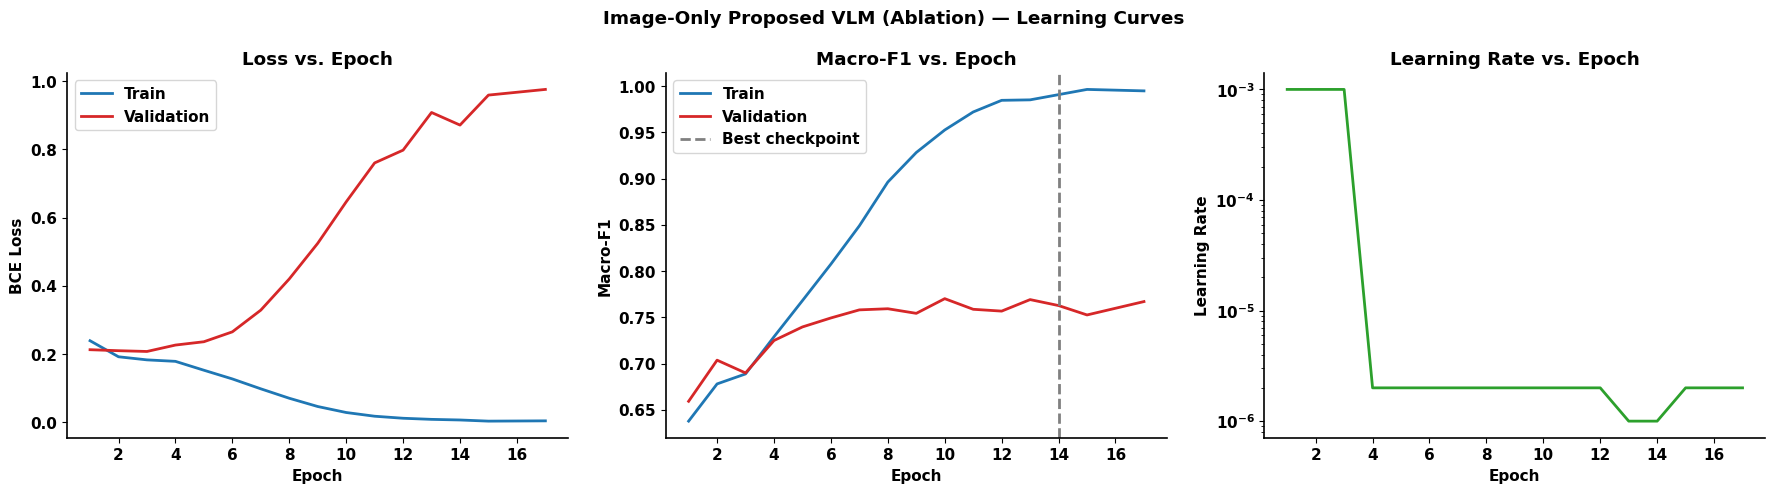

Saved: /content/drive/MyDrive/ROCOv2/Prepared/Ablation/ImageOnly_VLM/figures/learning_curves.pdf
Saved: /content/drive/MyDrive/ROCOv2/Prepared/Ablation/ImageOnly_VLM/figures/learning_curves_300dpi.png


In [20]:
# ============================================================
# CELL 17 — LEARNING CURVES FIGURE
# ============================================================

import matplotlib.pyplot as plt

plt.rcParams.update({
    "font.weight": "bold", "axes.labelweight": "bold", "axes.titleweight": "bold",
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "font.size": 11, "axes.linewidth": 1.2, "lines.linewidth": 2.0,
})

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].plot(training_history_df["Epoch"], training_history_df["Train_Loss"], label="Train", color="#1f77b4")
axes[0].plot(training_history_df["Epoch"], training_history_df["Val_Loss"], label="Validation", color="#d62728")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("BCE Loss"); axes[0].set_title("Loss vs. Epoch")
axes[0].legend(frameon=True)

axes[1].plot(training_history_df["Epoch"], training_history_df["Train_Macro_F1"], label="Train", color="#1f77b4")
axes[1].plot(training_history_df["Epoch"], training_history_df["Val_Macro_F1"], label="Validation", color="#d62728")
axes[1].axvline(best_epoch_info["epoch"], color="gray", linestyle="--", label="Best checkpoint")
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Macro-F1"); axes[1].set_title("Macro-F1 vs. Epoch")
axes[1].legend(frameon=True)

axes[2].plot(training_history_df["Epoch"], training_history_df["Learning_Rate"], color="#2ca02c")
axes[2].set_xlabel("Epoch"); axes[2].set_ylabel("Learning Rate"); axes[2].set_title("Learning Rate vs. Epoch")
axes[2].set_yscale("log")

for ax in axes:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

fig.suptitle("Image-Only Proposed VLM (Ablation) — Learning Curves", fontweight="bold")
fig.tight_layout()
fig.savefig(IMG_LEARNING_CURVES_PDF, format="pdf", bbox_inches="tight")
fig.savefig(IMG_LEARNING_CURVES_PNG, format="png", dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", IMG_LEARNING_CURVES_PDF)
print("Saved:", IMG_LEARNING_CURVES_PNG)


## 17. Full multi-label evaluation function (identical design to Notebooks 05/07)

In [21]:
# ============================================================
# CELL 18 — FULL MULTI-LABEL EVALUATION FUNCTION
# ============================================================

from sklearn.metrics import (
    precision_recall_fscore_support, roc_auc_score, average_precision_score,
    hamming_loss, accuracy_score,
)

def full_multilabel_evaluation(y_true, y_score, threshold, label_names):
    y_pred = (y_score >= threshold).astype(int)
    n_labels = y_true.shape[1]

    micro_p, micro_r, micro_f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average="micro", zero_division=0)
    macro_p, macro_r, macro_f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average="macro", zero_division=0)
    _, _, weighted_f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average="weighted", zero_division=0)

    per_label_p, per_label_r, per_label_f1, per_label_support = precision_recall_fscore_support(
        y_true, y_pred, average=None, zero_division=0)

    hamming = hamming_loss(y_true, y_pred)
    subset_acc = accuracy_score(y_true, y_pred)

    per_label_roc_auc, per_label_pr_auc = [], []
    for c in range(n_labels):
        col_true = y_true[:, c]
        if len(np.unique(col_true)) < 2:
            per_label_roc_auc.append(np.nan)
            per_label_pr_auc.append(np.nan)
            continue
        per_label_roc_auc.append(roc_auc_score(col_true, y_score[:, c]))
        per_label_pr_auc.append(average_precision_score(col_true, y_score[:, c]))

    degenerate_labels = [label_names[c] for c in range(n_labels) if np.isnan(per_label_roc_auc[c])]

    try:
        micro_roc_auc = roc_auc_score(y_true, y_score, average="micro")
    except ValueError:
        micro_roc_auc = np.nan
    macro_roc_auc = float(np.nanmean(per_label_roc_auc)) if not all(np.isnan(per_label_roc_auc)) else np.nan

    try:
        micro_pr_auc = average_precision_score(y_true, y_score, average="micro")
    except ValueError:
        micro_pr_auc = np.nan
    macro_pr_auc = float(np.nanmean(per_label_pr_auc)) if not all(np.isnan(per_label_pr_auc)) else np.nan

    overall = {
        "Micro_Precision": micro_p, "Micro_Recall": micro_r, "Micro_F1": micro_f1,
        "Macro_Precision": macro_p, "Macro_Recall": macro_r, "Macro_F1": macro_f1,
        "Weighted_F1": weighted_f1, "Hamming_Loss": hamming, "Subset_Accuracy": subset_acc,
        "ROC_AUC_Micro": micro_roc_auc, "ROC_AUC_Macro": macro_roc_auc,
        "PR_AUC_Micro": micro_pr_auc, "PR_AUC_Macro": macro_pr_auc,
        "N_Samples": int(y_true.shape[0]), "Threshold": threshold,
        "Labels_With_Insufficient_Support": ", ".join(degenerate_labels) if degenerate_labels else "none",
    }

    per_label = pd.DataFrame({
        "Label_Name": label_names,
        "Precision": per_label_p, "Recall": per_label_r, "F1": per_label_f1,
        "Support": per_label_support, "ROC_AUC": per_label_roc_auc, "PR_AUC": per_label_pr_auc,
    })

    return overall, per_label, y_pred

print("full_multilabel_evaluation() defined.")


full_multilabel_evaluation() defined.


## 18. Load the best checkpoint and evaluate on Validation

In [22]:
# ============================================================
# CELL 19 — LOAD BEST CHECKPOINT, EVALUATE ON VALIDATION
# ============================================================

best_checkpoint = torch.load(IMG_BEST_MODEL_PATH, map_location=device)
biomedclip_model.visual.load_state_dict(best_checkpoint["vision_state_dict"])
classifier_head.load_state_dict(best_checkpoint["head_state_dict"])
biomedclip_model.eval()
classifier_head.eval()

print(f"Loaded best checkpoint: epoch={best_checkpoint['epoch']}, stage={best_checkpoint['stage']}, "
      f"validation_macro_f1={best_checkpoint['validation_macro_f1']:.4f}")

_, _, val_y_true, val_y_score, val_ids = evaluate_epoch(dataloaders["validation"])
val_overall, val_per_label, val_y_pred = full_multilabel_evaluation(
    val_y_true, val_y_score, TRAINING_CONFIG["decision_threshold"], LABEL_NAMES,
)
val_per_label.insert(0, "Split", "validation")

val_metrics_df = pd.DataFrame([val_overall])
safe_save_csv(IMG_VAL_METRICS_PATH, val_metrics_df)

print("\nVALIDATION METRICS (development-time; not the final result):")
display(val_metrics_df)


Loaded best checkpoint: epoch=10, stage=2, validation_macro_f1=0.7703
Saved: /content/drive/MyDrive/ROCOv2/Prepared/Ablation/ImageOnly_VLM/ablation_image_only_vlm_validation_metrics.csv

VALIDATION METRICS (development-time; not the final result):


,Micro_Precision,Micro_Recall,Micro_F1,Macro_Precision,Macro_Recall,Macro_F1,Weighted_F1,Hamming_Loss,Subset_Accuracy,ROC_AUC_Micro,ROC_AUC_Macro,PR_AUC_Micro,PR_AUC_Macro,N_Samples,Threshold,Labels_With_Insufficient_Support
0,0.859906,0.884511,0.872035,0.781775,0.786289,0.770334,0.872726,0.022739,0.722171,0.988602,0.974001,0.934921,0.819847,9819,0.5,none


## 19. FINAL TEST EVALUATION — Test touched here only for this model

Same protocol as every prior notebook: fixed 0.5 threshold, computed once,
after every architecture/training decision has already been frozen.

In [23]:
# ============================================================
# CELL 20 — FINAL TEST EVALUATION (TEST TOUCHED HERE ONLY)
# ============================================================

print("=" * 80)
print("FINAL TEST EVALUATION (IMAGE-ONLY ABLATION) — TEST SET TOUCHED HERE ONLY")
print("=" * 80)

_, _, test_y_true, test_y_score, test_ids = evaluate_epoch(dataloaders["test"])
test_overall, test_per_label, test_y_pred = full_multilabel_evaluation(
    test_y_true, test_y_score, TRAINING_CONFIG["decision_threshold"], LABEL_NAMES,
)
test_per_label.insert(0, "Split", "test")

test_metrics_df = pd.DataFrame([test_overall])
safe_save_csv(IMG_TEST_METRICS_PATH, test_metrics_df)

per_label_metrics_df = pd.concat([val_per_label, test_per_label], ignore_index=True)
safe_save_csv(IMG_PER_LABEL_METRICS_PATH, per_label_metrics_df)

print("\nFINAL TEST RESULTS (image-only ablation, original Test set, n={:,}):".format(len(test_y_true)))
display(test_metrics_df)


FINAL TEST EVALUATION (IMAGE-ONLY ABLATION) — TEST SET TOUCHED HERE ONLY
Saved: /content/drive/MyDrive/ROCOv2/Prepared/Ablation/ImageOnly_VLM/ablation_image_only_vlm_test_metrics.csv
Saved: /content/drive/MyDrive/ROCOv2/Prepared/Ablation/ImageOnly_VLM/ablation_image_only_vlm_per_label_metrics.csv

FINAL TEST RESULTS (image-only ablation, original Test set, n=9,870):


,Micro_Precision,Micro_Recall,Micro_F1,Macro_Precision,Macro_Recall,Macro_F1,Weighted_F1,Hamming_Loss,Subset_Accuracy,ROC_AUC_Micro,ROC_AUC_Macro,PR_AUC_Micro,PR_AUC_Macro,N_Samples,Threshold,Labels_With_Insufficient_Support
0,0.86665,0.889495,0.877924,0.738931,0.7702,0.74902,0.877733,0.02171,0.733739,0.989107,0.975884,0.937854,0.83235,9870,0.5,none


## 20. Save predictions (needed by Part B for the Test-final comparison)

In [24]:
# ============================================================
# CELL 21 — SAVE PREDICTIONS (VALIDATION + TEST)
# ============================================================

def build_predictions_df(split_name, ids, y_true, y_score, y_pred):
    rows = {"ID": ids, "Split": split_name}
    for i, col in enumerate(LABEL_COLUMNS):
        rows[f"{col}_true"] = y_true[:, i]
        rows[f"{col}_prob"] = y_score[:, i]
        rows[f"{col}_pred"] = y_pred[:, i]
    return pd.DataFrame(rows)

assert len(val_ids) == len(val_y_true), "val_ids length must match val_y_true rows."
assert len(test_ids) == len(test_y_true), "test_ids length must match test_y_true rows."

image_only_predictions_df = pd.concat([
    build_predictions_df("validation", val_ids, val_y_true, val_y_score, val_y_pred),
    build_predictions_df("test", test_ids, test_y_true, test_y_score, test_y_pred),
], ignore_index=True)

safe_save_csv(IMG_PREDICTIONS_PATH, image_only_predictions_df)


Saved: /content/drive/MyDrive/ROCOv2/Prepared/Ablation/ImageOnly_VLM/ablation_image_only_vlm_predictions.csv


## 21. Reproducibility record (Part A)

In [25]:
# ============================================================
# CELL 22 — REPRODUCIBILITY.JSON (PART A)
# ============================================================

def package_version(module_name):
    try:
        module = __import__(module_name)
        return getattr(module, "__version__", "unknown")
    except Exception:
        return "not installed"

image_only_reproducibility = {
    "notebook": "14_ROCOv2_Ablation_Study (Part A — Image-only VLM)",
    "python_version": sys.version,
    "platform": platform.platform(),
    "pytorch_version": torch.__version__,
    "open_clip_version": package_version("open_clip"),
    "sklearn_version": package_version("sklearn"),
    "numpy_version": np.__version__,
    "pandas_version": pd.__version__,
    "cuda_version": torch.version.cuda if torch.cuda.is_available() else None,
    "gpu_name": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
    "mixed_precision_enabled": AMP_ENABLED,
    "random_seed": SEED,
    "checkpoint": BIOMEDCLIP_CHECKPOINT,
    "training_config": TRAINING_CONFIG,
    "best_epoch": best_epoch_info,
    "modality_at_inference": "image only",
}
safe_save_json(IMG_REPRODUCIBILITY_PATH, image_only_reproducibility)
print("\nPart A (Image-only Proposed VLM training and evaluation) complete.")


Saved: /content/drive/MyDrive/ROCOv2/Prepared/Ablation/ImageOnly_VLM/reproducibility.json

Part A (Image-only Proposed VLM training and evaluation) complete.


# PART B — CAPTION-ABLATION COMPARISON (IMAGE-ONLY VS. IMAGE+CAPTION)

## 22. Load both models' predictions and filter to Test-final

The Image+caption model's predictions come from Notebook 07's already-
saved `vlm_predictions.csv` — no re-inference. Both prediction sets are
filtered to the exact same Test-final ID set (Notebook 08), so this is an
apples-to-apples comparison on identical samples, mirroring how Notebook
08 re-derived the three main models' Test-final metrics from their
already-saved Test predictions.

In [26]:
# ============================================================
# CELL 23 — LOAD AND ALIGN BOTH MODELS' PREDICTIONS ON TEST-FINAL
# ============================================================

image_caption_predictions_df = pd.read_csv(VLM_PREDICTIONS_PATH)
image_only_predictions_df = pd.read_csv(IMG_PREDICTIONS_PATH)

def prepare_test_final_arrays(predictions_df, label_columns, test_final_id_set):
    df = predictions_df[predictions_df["Split"] == "test"].copy()
    df = df[df["ID"].astype(str).isin(test_final_id_set)].sort_values("ID").reset_index(drop=True)
    y_true = df[[f"{c}_true" for c in label_columns]].to_numpy(dtype=bool)
    y_score = df[[f"{c}_prob" for c in label_columns]].to_numpy(dtype=float)
    return df["ID"].astype(str).to_numpy(), y_true, y_score

ids_caption, y_true_caption, y_score_caption = prepare_test_final_arrays(
    image_caption_predictions_df, LABEL_COLUMNS, test_final_ids)
ids_image_only, y_true_image_only, y_score_image_only = prepare_test_final_arrays(
    image_only_predictions_df, LABEL_COLUMNS, test_final_ids)

assert len(ids_caption) == len(test_final_ids), (
    f"Image+caption Test-final row count mismatch: got {len(ids_caption)}, "
    f"expected {len(test_final_ids)}."
)
assert len(ids_image_only) == len(test_final_ids), (
    f"Image-only Test-final row count mismatch: got {len(ids_image_only)}, "
    f"expected {len(test_final_ids)}."
)
assert list(ids_caption) == list(ids_image_only), (
    "Sample order/ID mismatch between the two models' Test-final subsets — "
    "paired comparison requires identical row-for-row alignment."
)
assert np.array_equal(y_true_caption, y_true_image_only), (
    "Ground-truth label mismatch between the two models' Test-final subsets — "
    "both must be evaluated against the same true labels."
)

print(f"Aligned {len(ids_caption):,} Test-final samples across both models.")
print("Row-for-row ID and ground-truth alignment: PASS.")


Aligned 4,935 Test-final samples across both models.
Row-for-row ID and ground-truth alignment: PASS.


## 23. Overall and per-label Test-final metrics for both variants

In [27]:
# ============================================================
# CELL 24 — OVERALL AND PER-LABEL METRICS (BOTH VARIANTS, TEST-FINAL)
# ============================================================

caption_overall, caption_per_label, _ = full_multilabel_evaluation(
    y_true_caption.astype(int), y_score_caption, 0.5, LABEL_NAMES)
image_only_overall, image_only_per_label, _ = full_multilabel_evaluation(
    y_true_image_only.astype(int), y_score_image_only, 0.5, LABEL_NAMES)

overall_comparison_df = pd.DataFrame([
    {"Variant": "Image-only Proposed VLM", **image_only_overall},
    {"Variant": "Image+caption Proposed VLM (Notebook 07)", **caption_overall},
])
safe_save_csv(CAPTION_COMPARISON_OVERALL_PATH, overall_comparison_df)
print("Overall Test-final comparison:")
display(overall_comparison_df[["Variant", "Micro_F1", "Macro_F1", "Hamming_Loss",
                                "Subset_Accuracy", "ROC_AUC_Macro", "N_Samples"]])

per_label_comparison_df = pd.DataFrame({
    "Label_Name": LABEL_NAMES,
    "Support_Test_Final": caption_per_label["Support"].to_numpy(),
    "Image_Only_F1": image_only_per_label["F1"].to_numpy(),
    "Image_Caption_F1": caption_per_label["F1"].to_numpy(),
})
per_label_comparison_df["Caption_F1_Delta"] = (
    per_label_comparison_df["Image_Caption_F1"] - per_label_comparison_df["Image_Only_F1"]
)
per_label_comparison_df = per_label_comparison_df.sort_values("Caption_F1_Delta", ascending=False)
safe_save_csv(CAPTION_COMPARISON_PER_LABEL_PATH, per_label_comparison_df)
print("\nPer-label F1, sorted by caption contribution (Image+caption minus Image-only):")
display(per_label_comparison_df)


Saved: /content/drive/MyDrive/ROCOv2/Prepared/Ablation/ablation_caption_comparison_overall.csv
Overall Test-final comparison:


,Variant,Micro_F1,Macro_F1,Hamming_Loss,Subset_Accuracy,ROC_AUC_Macro,N_Samples
0,Image-only Proposed VLM,0.878501,0.747732,0.021536,0.733536,0.974560,4935
1,Image+caption Proposed VLM (Notebook 07),0.928526,0.831051,0.012631,0.863425,0.995362,4935


Saved: /content/drive/MyDrive/ROCOv2/Prepared/Ablation/ablation_caption_comparison_per_label.csv

Per-label F1, sorted by caption contribution (Image+caption minus Image-only):


,Label_Name,Support_Test_Final,Image_Only_F1,Image_Caption_F1,Caption_F1_Delta
0,Abdomen,276,0.476190,0.857143,0.380952
5,Pelvis,252,0.482906,0.856597,0.373691
8,Vertebral column,98,0.613861,0.830000,0.216139
13,Chest,674,0.748924,0.937870,0.188946
12,Sagittal,169,0.692098,0.845304,0.153206
2,Breast,18,0.642857,0.702703,0.059846
14,Upper Extremity,70,0.820144,0.874172,0.054028
3,Lower Extremity,230,0.848233,0.870159,0.021927
7,Bone structure of cranium,204,0.908213,0.926471,0.018258
1,Angiogram,210,0.769517,0.781308,0.011792


## 24. Paired bootstrap significance test (identical methodology to Notebook 13)

In [28]:
# ============================================================
# CELL 25 — PAIRED BOOTSTRAP SIGNIFICANCE (IMAGE-ONLY VS. IMAGE+CAPTION)
# ============================================================

def fast_macro_f1(y_true, y_pred):
    tp = (y_true & y_pred).sum(axis=0)
    fp = ((~y_true) & y_pred).sum(axis=0)
    fn = (y_true & (~y_pred)).sum(axis=0)
    precision = tp / np.clip(tp + fp, 1, None)
    recall = tp / np.clip(tp + fn, 1, None)
    f1 = np.where((precision + recall) > 0, 2 * precision * recall / np.clip(precision + recall, 1e-12, None), 0.0)
    return float(f1.mean())

def fast_micro_f1(y_true, y_pred):
    tp = (y_true & y_pred).sum()
    fp = ((~y_true) & y_pred).sum()
    fn = (y_true & (~y_pred)).sum()
    precision = tp / max(tp + fp, 1)
    recall = tp / max(tp + fn, 1)
    return float(2 * precision * recall / max(precision + recall, 1e-12))

N_BOOTSTRAP = 2000
CI_LEVEL = 0.95
alpha = 1 - CI_LEVEL

y_pred_caption = (y_score_caption >= 0.5)
y_pred_image_only = (y_score_image_only >= 0.5)

N = len(ids_caption)
rng = np.random.RandomState(SEED)

boot_macro = {"image_only": np.empty(N_BOOTSTRAP), "image_caption": np.empty(N_BOOTSTRAP)}
boot_micro = {"image_only": np.empty(N_BOOTSTRAP), "image_caption": np.empty(N_BOOTSTRAP)}

for b in range(N_BOOTSTRAP):
    idx = rng.randint(0, N, size=N)
    boot_macro["image_only"][b] = fast_macro_f1(y_true_image_only[idx], y_pred_image_only[idx])
    boot_micro["image_only"][b] = fast_micro_f1(y_true_image_only[idx], y_pred_image_only[idx])
    boot_macro["image_caption"][b] = fast_macro_f1(y_true_caption[idx], y_pred_caption[idx])
    boot_micro["image_caption"][b] = fast_micro_f1(y_true_caption[idx], y_pred_caption[idx])

bootstrap_rows = []
for metric_name, boot_dict in [("Macro_F1", boot_macro), ("Micro_F1", boot_micro)]:
    diff = boot_dict["image_caption"] - boot_dict["image_only"]
    lower, upper = np.percentile(diff, [100 * alpha / 2, 100 * (1 - alpha / 2)])
    p_ge = float((diff >= 0).mean())
    p_le = float((diff <= 0).mean())
    p_value = min(1.0, 2 * min(p_ge, p_le))
    significant = (lower > 0) or (upper < 0)
    bootstrap_rows.append({
        "Comparison": "Image+caption minus Image-only", "Metric": metric_name,
        "Mean_Difference": float(diff.mean()), "CI_Lower": float(lower), "CI_Upper": float(upper),
        "Bootstrap_P_Value": p_value, "Significant_at_0.05": bool(significant),
        "N_Bootstrap": N_BOOTSTRAP, "N_Test_Final": N,
    })

caption_bootstrap_df = pd.DataFrame(bootstrap_rows)
safe_save_csv(CAPTION_BOOTSTRAP_CI_PATH, caption_bootstrap_df)
print("Paired bootstrap significance, Image+caption vs. Image-only, Test-final:")
display(caption_bootstrap_df)


Saved: /content/drive/MyDrive/ROCOv2/Prepared/Ablation/ablation_caption_bootstrap_ci.csv
Paired bootstrap significance, Image+caption vs. Image-only, Test-final:


,Comparison,Metric,Mean_Difference,CI_Lower,CI_Upper,Bootstrap_P_Value,Significant_at_0.05,N_Bootstrap,N_Test_Final
0,Image+caption minus Image-only,Macro_F1,0.083735,0.068547,0.099053,0.0,True,2000,4935
1,Image+caption minus Image-only,Micro_F1,0.050027,0.045130,0.054569,0.0,True,2000,4935


## 25. Caption-ablation comparison figure

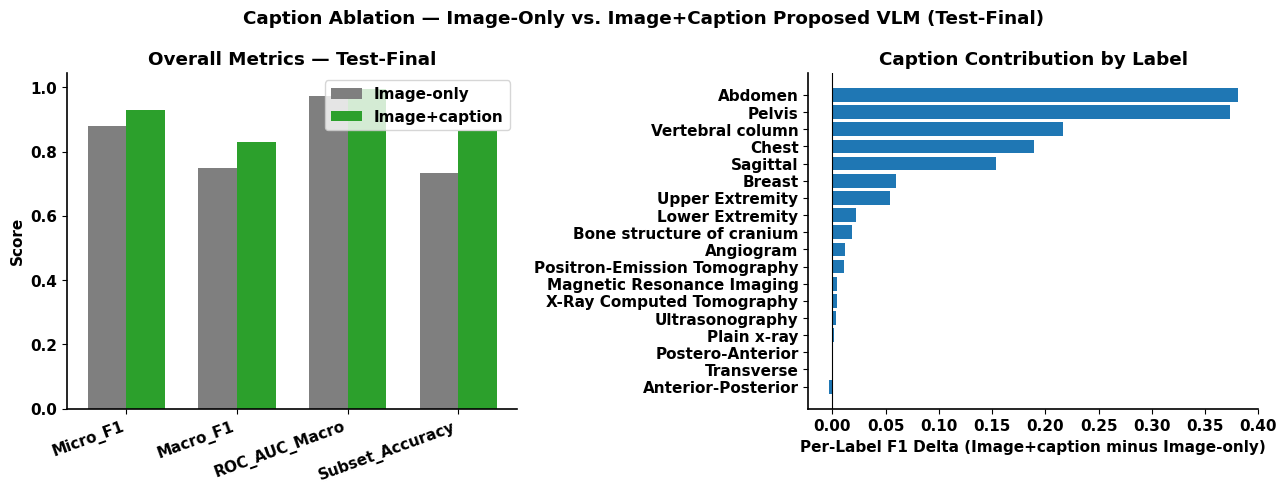

Saved: /content/drive/MyDrive/ROCOv2/Prepared/Ablation/figures/caption_ablation_comparison.pdf
Saved: /content/drive/MyDrive/ROCOv2/Prepared/Ablation/figures/caption_ablation_comparison_300dpi.png


In [29]:
# ============================================================
# CELL 26 — CAPTION-ABLATION COMPARISON FIGURE
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

metrics_to_plot = ["Micro_F1", "Macro_F1", "ROC_AUC_Macro", "Subset_Accuracy"]
x = np.arange(len(metrics_to_plot))
width = 0.35
axes[0].bar(x - width / 2, [image_only_overall[m] for m in metrics_to_plot], width,
            label="Image-only", color="#7f7f7f")
axes[0].bar(x + width / 2, [caption_overall[m] for m in metrics_to_plot], width,
            label="Image+caption", color="#2ca02c")
axes[0].set_xticks(x); axes[0].set_xticklabels(metrics_to_plot, rotation=20, ha="right")
axes[0].set_ylabel("Score"); axes[0].set_title("Overall Metrics — Test-Final")
axes[0].legend(frameon=True)

sorted_delta = per_label_comparison_df.sort_values("Caption_F1_Delta")
axes[1].barh(sorted_delta["Label_Name"], sorted_delta["Caption_F1_Delta"], color="#1f77b4")
axes[1].axvline(0, color="black", linewidth=0.8)
axes[1].set_xlabel("Per-Label F1 Delta (Image+caption minus Image-only)")
axes[1].set_title("Caption Contribution by Label")

for ax in axes:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

fig.suptitle("Caption Ablation — Image-Only vs. Image+Caption Proposed VLM (Test-Final)", fontweight="bold")
fig.tight_layout()
fig.savefig(CAPTION_COMPARISON_FIGURE_PDF, format="pdf", bbox_inches="tight")
fig.savefig(CAPTION_COMPARISON_FIGURE_PNG, format="png", dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", CAPTION_COMPARISON_FIGURE_PDF)
print("Saved:", CAPTION_COMPARISON_FIGURE_PNG)


# PART C — TRUST-SCORE COMPONENT ABLATION

## 26. Load Notebook 11's per-sample-label trust-score components

No recalibration and no re-run of the conformal or counterfactual search:
`trust_scores_per_sample_label.csv` already contains `Conformal_Component`,
`Counterfactual_Component`, `Original_Prob`, and `True_Label` broken out
per row, exactly as Notebook 11 computed them.

In [30]:
# ============================================================
# CELL 27 — LOAD TRUST-SCORE COMPONENTS
# ============================================================

trust_df = pd.read_csv(TRUST_SCORES_PATH)

required_cols = {"ID", "Label_Name", "True_Label", "Original_Prob",
                  "Conformal_Component", "Counterfactual_Component", "Trust_Score"}
missing_cols = required_cols - set(trust_df.columns)
if missing_cols:
    raise KeyError(
        f"trust_scores_per_sample_label.csv is missing expected column(s): {missing_cols}. "
        "This notebook reuses Notebook 11's own saved components and does not recompute them."
    )

print(f"Loaded {len(trust_df):,} sample-label rows "
      f"({trust_df['ID'].nunique():,} unique samples x {trust_df['Label_Name'].nunique()} labels).")
display(trust_df[["ID", "Label_Name", "Original_Prob", "Conformal_Component",
                   "Counterfactual_Component", "Trust_Score"]].head(5))


Loaded 9,000 sample-label rows (500 unique samples x 18 labels).


,ID,Label_Name,Original_Prob,Conformal_Component,Counterfactual_Component,Trust_Score
0,ROCOv2_2023_test_002356,Abdomen,2.453577e-11,1.0,0.521977,0.760989
1,ROCOv2_2023_test_002356,Angiogram,3.611533e-05,0.5,0.252147,0.376073
2,ROCOv2_2023_test_002356,Breast,6.346260e-08,0.5,0.462707,0.481353
3,ROCOv2_2023_test_002356,Lower Extremity,3.554896e-05,0.5,0.258146,0.379073
4,ROCOv2_2023_test_002356,Magnetic Resonance Imaging,5.893247e-06,1.0,0.299165,0.649583


## 27. Define the four trust-score variants

- **Full composite** — Notebook 11's own score, reloaded unchanged.
- **Conformal-only** — the conformal component alone, i.e. what Notebook
  11's trust score would be with `counterfactual_weight = 0`.
- **Counterfactual-only** — the counterfactual component alone, i.e. what
  Notebook 11's trust score would be with `conformal_weight = 0`.
- **Raw-confidence-only (baseline, not one of the four originally
  requested arms — added so "beyond raw confidence" is actually
  testable)** — `|Original_Prob - 0.5| * 2`, a model-confidence measure on
  the same [0, 1] scale (0 = maximally uncertain at the 0.5 boundary,
  1 = maximally confident at either extreme), using no conformal or
  counterfactual information at all.

In [31]:
# ============================================================
# CELL 28 — DEFINE TRUST-SCORE VARIANTS
# ============================================================

trust_df["Variant_Full_Composite"] = trust_df["Trust_Score"]
trust_df["Variant_Conformal_Only"] = trust_df["Conformal_Component"]
trust_df["Variant_Counterfactual_Only"] = trust_df["Counterfactual_Component"]
trust_df["Variant_Raw_Confidence_Only"] = (trust_df["Original_Prob"] - 0.5).abs() * 2.0

VARIANT_COLUMNS = {
    "Full composite (conformal + counterfactual)": "Variant_Full_Composite",
    "Conformal component only": "Variant_Conformal_Only",
    "Counterfactual component only": "Variant_Counterfactual_Only",
    "Raw model confidence only (baseline)": "Variant_Raw_Confidence_Only",
}

trust_df["Predicted_Label"] = (trust_df["Original_Prob"] >= 0.5).astype(int)
trust_df["Correct"] = (trust_df["Predicted_Label"] == trust_df["True_Label"]).astype(int)

print("Trust-score variants defined:")
for display_name, col in VARIANT_COLUMNS.items():
    print(f"  {display_name:48s} -> {col} "
          f"(range [{trust_df[col].min():.4f}, {trust_df[col].max():.4f}])")


Trust-score variants defined:
  Full composite (conformal + counterfactual)      -> Variant_Full_Composite (range [0.2500, 0.9155])
  Conformal component only                         -> Variant_Conformal_Only (range [0.5000, 1.0000])
  Counterfactual component only                    -> Variant_Counterfactual_Only (range [0.0000, 1.0000])
  Raw model confidence only (baseline)             -> Variant_Raw_Confidence_Only (range [0.0340, 1.0000])


## 28. Validate each variant — quintile-bin accuracy + Spearman correlation

Identical methodology to Notebook 11 (`N_VALIDATION_BINS = 5`, `Correct`
defined the same way), applied independently to each variant so the four
are directly comparable.

In [32]:
# ============================================================
# CELL 29 — VALIDATE EACH VARIANT
# ============================================================

N_VALIDATION_BINS = 5

variant_summary_rows = []
bin_validation_rows = []

for display_name, col in VARIANT_COLUMNS.items():
    spearman_corr = trust_df[col].corr(trust_df["Correct"], method="spearman")

    bin_col = f"{col}_Bin"
    trust_df[bin_col] = pd.qcut(trust_df[col], q=N_VALIDATION_BINS, duplicates="drop")
    binned = (
        trust_df.groupby(bin_col, observed=True)
        .agg(Mean_Score=(col, "mean"), Accuracy=("Correct", "mean"), N=("Correct", "count"))
        .reset_index(drop=True)
        .sort_values("Mean_Score")
    )
    for _, row in binned.iterrows():
        bin_validation_rows.append({
            "Variant": display_name, "Mean_Score": row["Mean_Score"],
            "Accuracy": row["Accuracy"], "N": int(row["N"]),
        })

    lowest_bin_acc = binned.iloc[0]["Accuracy"]
    highest_bin_acc = binned.iloc[-1]["Accuracy"]
    n_bins_actual = len(binned)
    is_monotonic = bool(np.all(np.diff(binned["Accuracy"].to_numpy()) >= -1e-9))

    variant_summary_rows.append({
        "Variant": display_name,
        "Spearman_r_vs_Correctness": float(spearman_corr),
        "N_Bins": n_bins_actual,
        "Lowest_Bin_Accuracy": float(lowest_bin_acc),
        "Highest_Bin_Accuracy": float(highest_bin_acc),
        "Bin_Accuracy_Spread": float(highest_bin_acc - lowest_bin_acc),
        "Monotonic_Increasing": is_monotonic,
    })

variant_summary_df = pd.DataFrame(variant_summary_rows).sort_values(
    "Spearman_r_vs_Correctness", ascending=False)
bin_validation_df = pd.DataFrame(bin_validation_rows)

safe_save_csv(TRUST_VARIANT_SUMMARY_PATH, variant_summary_df)
safe_save_csv(TRUST_VARIANT_VALIDATION_PATH, bin_validation_df)

print("Trust-score variant validation summary (ranked by Spearman r vs. correctness):")
display(variant_summary_df)


Saved: /content/drive/MyDrive/ROCOv2/Prepared/Ablation/ablation_trust_score_variant_summary.csv
Saved: /content/drive/MyDrive/ROCOv2/Prepared/Ablation/ablation_trust_score_variant_validation.csv
Trust-score variant validation summary (ranked by Spearman r vs. correctness):


,Variant,Spearman_r_vs_Correctness,N_Bins,Lowest_Bin_Accuracy,Highest_Bin_Accuracy,Bin_Accuracy_Spread,Monotonic_Increasing
3,Raw model confidence only (baseline),0.173206,5,0.944444,1.000000,0.055556,True
2,Counterfactual component only,0.170444,5,0.945556,1.000000,0.054444,True
0,Full composite (conformal + counterfactual),0.165855,5,0.949444,1.000000,0.050556,True
1,Conformal component only,0.161605,1,0.988778,0.988778,0.000000,True


## 29. Trust-score component ablation figure

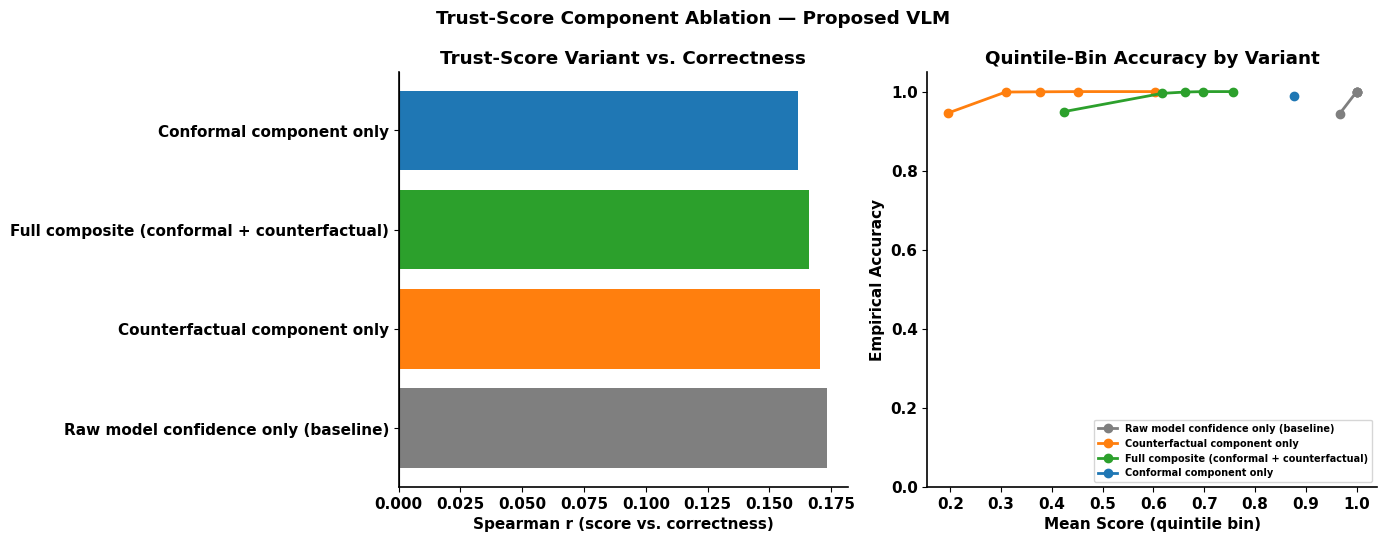

Saved: /content/drive/MyDrive/ROCOv2/Prepared/Ablation/figures/trust_score_component_ablation.pdf
Saved: /content/drive/MyDrive/ROCOv2/Prepared/Ablation/figures/trust_score_component_ablation_300dpi.png


In [33]:
# ============================================================
# CELL 30 — TRUST-SCORE COMPONENT ABLATION FIGURE
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

order = variant_summary_df["Variant"].tolist()
colors = {"Full composite (conformal + counterfactual)": "#2ca02c",
          "Conformal component only": "#1f77b4",
          "Counterfactual component only": "#ff7f0e",
          "Raw model confidence only (baseline)": "#7f7f7f"}

axes[0].barh(variant_summary_df["Variant"], variant_summary_df["Spearman_r_vs_Correctness"],
             color=[colors[v] for v in variant_summary_df["Variant"]])
axes[0].set_xlabel("Spearman r (score vs. correctness)")
axes[0].set_title("Trust-Score Variant vs. Correctness")
axes[0].axvline(0, color="black", linewidth=0.8)

for variant_name in order:
    sub = bin_validation_df[bin_validation_df["Variant"] == variant_name].sort_values("Mean_Score")
    axes[1].plot(sub["Mean_Score"], sub["Accuracy"], marker="o", label=variant_name,
                 color=colors[variant_name])
axes[1].set_xlabel("Mean Score (quintile bin)")
axes[1].set_ylabel("Empirical Accuracy")
axes[1].set_title("Quintile-Bin Accuracy by Variant")
axes[1].legend(fontsize=7, frameon=True, loc="lower right")
axes[1].set_ylim(0, 1.05)

for ax in axes:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

fig.suptitle("Trust-Score Component Ablation — Proposed VLM", fontweight="bold")
fig.tight_layout()
fig.savefig(TRUST_VARIANT_FIGURE_PDF, format="pdf", bbox_inches="tight")
fig.savefig(TRUST_VARIANT_FIGURE_PNG, format="png", dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", TRUST_VARIANT_FIGURE_PDF)
print("Saved:", TRUST_VARIANT_FIGURE_PNG)


# PART D — REPRODUCIBILITY AND ARTIFACT MANIFEST

## 30. Reproducibility record (whole notebook)

In [34]:
# ============================================================
# CELL 31 — REPRODUCIBILITY.JSON (WHOLE NOTEBOOK)
# ============================================================

reproducibility = {
    "notebook": "14_ROCOv2_Ablation_Study",
    "python_version": sys.version,
    "platform": platform.platform(),
    "pytorch_version": torch.__version__,
    "open_clip_version": package_version("open_clip"),
    "sklearn_version": package_version("sklearn"),
    "numpy_version": np.__version__,
    "pandas_version": pd.__version__,
    "cuda_version": torch.version.cuda if torch.cuda.is_available() else None,
    "gpu_name": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
    "random_seed": SEED,
    "part_a_image_only_vlm": {
        "checkpoint": BIOMEDCLIP_CHECKPOINT,
        "best_epoch": best_epoch_info,
        "total_epochs_run": int(global_epoch),
    },
    "part_b_caption_ablation": {
        "n_bootstrap": N_BOOTSTRAP, "ci_level": CI_LEVEL,
        "n_test_final_samples": int(N),
    },
    "part_c_trust_score_ablation": {
        "n_validation_bins": N_VALIDATION_BINS,
        "variants": list(VARIANT_COLUMNS.keys()),
        "source_notebook_11_file": str(TRUST_SCORES_PATH),
    },
}
safe_save_json(REPRODUCIBILITY_PATH, reproducibility)


Saved: /content/drive/MyDrive/ROCOv2/Prepared/Ablation/reproducibility.json


## 31. Artifact manifest and final report

In [35]:
# ============================================================
# CELL 32 — ARTIFACT MANIFEST + FINAL REPORT
# ============================================================

artifact_paths = [
    IMG_CONFIG_PATH, IMG_HISTORY_PATH, IMG_VAL_METRICS_PATH, IMG_TEST_METRICS_PATH,
    IMG_PER_LABEL_METRICS_PATH, IMG_PREDICTIONS_PATH, IMG_BEST_MODEL_PATH, IMG_LAST_MODEL_PATH,
    IMG_LEARNING_CURVES_PDF, IMG_LEARNING_CURVES_PNG, IMG_REPRODUCIBILITY_PATH,
    CAPTION_COMPARISON_OVERALL_PATH, CAPTION_COMPARISON_PER_LABEL_PATH, CAPTION_BOOTSTRAP_CI_PATH,
    CAPTION_COMPARISON_FIGURE_PDF, CAPTION_COMPARISON_FIGURE_PNG,
    TRUST_VARIANT_VALIDATION_PATH, TRUST_VARIANT_SUMMARY_PATH,
    TRUST_VARIANT_FIGURE_PDF, TRUST_VARIANT_FIGURE_PNG,
    REPRODUCIBILITY_PATH,
]

manifest = [{
    "Artifact": p.name, "Path": str(p), "Exists": p.exists(),
    "Size_KB": round(p.stat().st_size / 1024, 2) if p.exists() else None,
} for p in artifact_paths]
artifact_manifest_df = pd.DataFrame(manifest)
display(artifact_manifest_df)

manifest_missing = [m["Path"] for m in manifest if not m["Exists"]]
notebook_status = "COMPLETE" if not manifest_missing else f"NOT READY — missing: {manifest_missing}"

safe_save_json(MANIFEST_PATH, {"artifacts": manifest, "status": notebook_status})

caption_sig_row = caption_bootstrap_df[caption_bootstrap_df["Metric"] == "Macro_F1"].iloc[0]
best_trust_variant = variant_summary_df.iloc[0]
raw_confidence_row = variant_summary_df[
    variant_summary_df["Variant"] == "Raw model confidence only (baseline)"
].iloc[0]
full_composite_row = variant_summary_df[
    variant_summary_df["Variant"] == "Full composite (conformal + counterfactual)"
].iloc[0]

print("\n" + "=" * 60)
print("ROCOv2 ABLATION STUDY — FINAL REPORT")
print("=" * 60)

_part_a_test_n = len(test_y_true)
_part_a_test_macro_f1 = test_overall['Macro_F1']
print(f'''
------------------------------------------------------------
PART A — IMAGE-ONLY PROPOSED VLM
------------------------------------------------------------
Best epoch: {best_epoch_info['epoch']} (stage {best_epoch_info['stage']})
Best Validation Macro-F1: {best_val_macro_f1:.4f}
Test (original, n={_part_a_test_n:,}) Macro-F1: {_part_a_test_macro_f1:.4f}
''')

print(f'''------------------------------------------------------------
PART B — CAPTION-ABLATION COMPARISON (TEST-FINAL, n={N})
------------------------------------------------------------
Image-only Macro-F1:      {image_only_overall['Macro_F1']:.4f}
Image+caption Macro-F1:   {caption_overall['Macro_F1']:.4f}
Mean difference (caption - image-only): {caption_sig_row['Mean_Difference']:.4f}
95% bootstrap CI: [{caption_sig_row['CI_Lower']:.4f}, {caption_sig_row['CI_Upper']:.4f}]
Significant at 0.05: {caption_sig_row['Significant_at_0.05']}

Interpretation: captions contribute a {'statistically significant' if caption_sig_row['Significant_at_0.05'] else 'not statistically significant'}
improvement over the image-only variant on Macro-F1. This quantifies,
for the first time in this pipeline, the caption-assisted-evaluation
caveat documented qualitatively in Notebook 07 and Chapter 4 (Section 4.5.3).
''')

print(f'''------------------------------------------------------------
PART C — TRUST-SCORE COMPONENT ABLATION
------------------------------------------------------------
Full composite Spearman r:        {full_composite_row['Spearman_r_vs_Correctness']:.4f}
Raw-confidence-only Spearman r:   {raw_confidence_row['Spearman_r_vs_Correctness']:.4f}
Best-performing variant (by Spearman r): {best_trust_variant['Variant']}

Interpretation: read Table (variant_summary_df) above directly — this
report does not characterize the comparison further, since which variant
is "better" depends on which validation criterion (Spearman r vs. bin
monotonicity vs. bin-accuracy spread) is weighted most heavily, and that
judgment call belongs in Chapter 5's discussion, not in this notebook's
auto-generated report.
''')

print("------------------------------------------------------------")
print("NOTEBOOK STATUS")
print("------------------------------------------------------------")
print(f"Ablation study: {'COMPLETE' if not manifest_missing else 'NOT READY'}")
print("Notebooks 01-13 modified: NO")
print("=" * 60)

print("\nSTOP — Notebook 14 (Ablation Study) is complete.")


,Artifact,Path,Exists,Size_KB
0,ablation_image_only_vlm_config.json,/content/drive/MyDrive/ROCOv2/Prepared/Ablatio...,True,6.44
1,ablation_image_only_vlm_training_history.csv,/content/drive/MyDrive/ROCOv2/Prepared/Ablatio...,True,1.81
2,ablation_image_only_vlm_validation_metrics.csv,/content/drive/MyDrive/ROCOv2/Prepared/Ablatio...,True,0.47
3,ablation_image_only_vlm_test_metrics.csv,/content/drive/MyDrive/ROCOv2/Prepared/Ablatio...,True,0.47
4,ablation_image_only_vlm_per_label_metrics.csv,/content/drive/MyDrive/ROCOv2/Prepared/Ablatio...,True,4.26
5,ablation_image_only_vlm_predictions.csv,/content/drive/MyDrive/ROCOv2/Prepared/Ablatio...,True,5143.18
6,ablation_image_only_vlm_best_model.pt,/content/drive/MyDrive/ROCOv2/Prepared/Ablatio...,True,337286.19
7,ablation_image_only_vlm_last_model.pt,/content/drive/MyDrive/ROCOv2/Prepared/Ablatio...,True,337286.19
8,learning_curves.pdf,/content/drive/MyDrive/ROCOv2/Prepared/Ablatio...,True,20.04
9,learning_curves_300dpi.png,/content/drive/MyDrive/ROCOv2/Prepared/Ablatio...,True,289.72


Saved: /content/drive/MyDrive/ROCOv2/Prepared/Ablation/artifact_manifest.json

ROCOv2 ABLATION STUDY — FINAL REPORT

------------------------------------------------------------
PART A — IMAGE-ONLY PROPOSED VLM
------------------------------------------------------------
Best epoch: 14 (stage 2)
Best Validation Macro-F1: 0.7629
Test (original, n=9,870) Macro-F1: 0.7490

------------------------------------------------------------
PART B — CAPTION-ABLATION COMPARISON (TEST-FINAL, n=4935)
------------------------------------------------------------
Image-only Macro-F1:      0.7477
Image+caption Macro-F1:   0.8311
Mean difference (caption - image-only): 0.0837
95% bootstrap CI: [0.0685, 0.0991]
Significant at 0.05: True

Interpretation: captions contribute a statistically significant
improvement over the image-only variant on Macro-F1. This quantifies,
for the first time in this pipeline, the caption-assisted-evaluation
caveat documented qualitatively in Notebook 07 and Chapter 4 (Section